# Using a known spatial pattern to assess the accuracy of `neuromodes.morphometry`

In this notebook we demonstrate the surface-based morphometry of `neuromodes.morphometry`. 

## Imports

In [118]:
import numpy as np
from numpy.typing import NDArray
from scipy import stats
import matplotlib.pyplot as plt

In [119]:
from brainspace.mesh.mesh_creation import build_polydata
from brainspace.vtk_interface.wrappers import BSPolyData

In [120]:
from neuromodes import EigenSolver
from neuromodes.io import fetch_example_surf
from neuromodes import mbm as mbm
from nsbutils.plotting import plot_surf

## Parameters/setup

In [121]:
# These can be changed freely
density = '4k'
n_subjects = 255
n_permutations = 100

# These are fixed for this demonstration
statTest = 'ttest'
alternative = 'two-sided'
permutationMethod = 'shuffle_rows'

In [122]:
# Load cortical surface mesh
surf, medmask = fetch_example_surf(density=density)
solver = EigenSolver(surf, mask=medmask)
n_verts = solver.n_verts

# Generate BSPolyData object for plotting
# known warning here from brainspace/vtk
bssurf: BSPolyData = build_polydata(surf.v, cells=surf.t) # type: ignore 


c:\Users\mehul\Documents\PhD\PYTHON\neuromodes\.venv\Lib\site-packages\brainspace\vtk_interface\wrappers\misc.py:100: DeprecationWarning: Call to deprecated method SetCells. (Use ImportLegacyFormat or SetData instead.) -- Deprecated since version 9.6.0.
  self.VTKObject.SetCells(n_cells, cells)


## Generate data

In [123]:
# Here we just use the y-coordinate (rescaled to [-1, 2]) as a simple spatial pattern for the expected t-statistic
spatial_pattern = np.interp(solver.geometry.v[:,1], (solver.geometry.v[:,1].min(), solver.geometry.v[:,1].max()), (-1, 2))

# Then the t and p values can be computed from the spatial pattern and the number of subjects
t_expected = spatial_pattern * np.sqrt(n_subjects / 2)
p_expected = 2 * stats.t.sf(np.abs(t_expected), df=2*n_subjects - 2)

In [124]:
# Here we generate synthetic data for two groups of subjects, with the expected spatial pattern added to one group. 
rng = np.random.default_rng(42)

# 1. Generate baseline noise and z-score across subjects (axis=1, ddof=1)
a_noise: NDArray = stats.zscore(rng.normal(size=(n_verts, n_subjects)), axis=1, ddof=1) # type: ignore
b_noise: NDArray = stats.zscore(rng.normal(size=(n_verts, n_subjects)), axis=1, ddof=1) # type: ignore

# 2. Enforce exact pooled variance = 1 across the two groups
sd = np.sqrt((np.var(a_noise, axis=1, ddof=1) + np.var(b_noise, axis=1, ddof=1)) / 2)

# 3. Construct group matrices with exact spatial pattern offset
data_a = a_noise / sd[:, np.newaxis]
data_b = b_noise / sd[:, np.newaxis] + spatial_pattern[:, np.newaxis]

We can visualise the first few example maps:

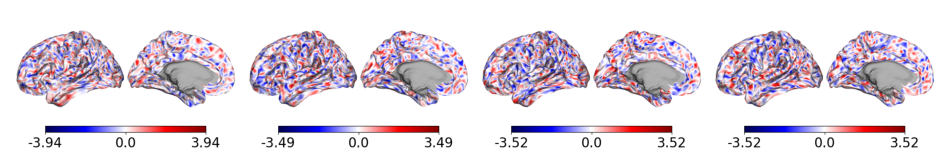

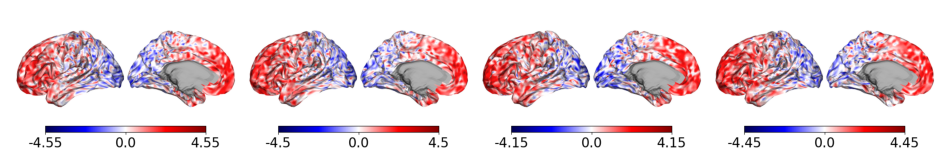

In [125]:
plot_surf(bssurf, solver.unmask_data(data_a[:,:4]), cmap='seismic', cbar=True, center=0)
plot_surf(bssurf, solver.unmask_data(data_b[:,:4]), cmap='seismic', cbar=True, center=0)

## Vertex-level t-test (surface based morphometry)

`neuromodes.morphometry` requires us to explicity construct design, response, and contrast matrices:

In [126]:
response = np.vstack((data_b.T, data_a.T))
design = np.kron(np.eye(2), np.ones((n_subjects, 1)))
contrast = np.array([[1, -1]])

We actually compute the vertex-level t-statistic using the function `mbm_generate_stat_maps`: 

In [127]:
t_observed = mbm.mbm_generate_stat_maps(design, response, contrast, statTest)

We can visualise the theoretical and observed vertex-wise t-statistics: 

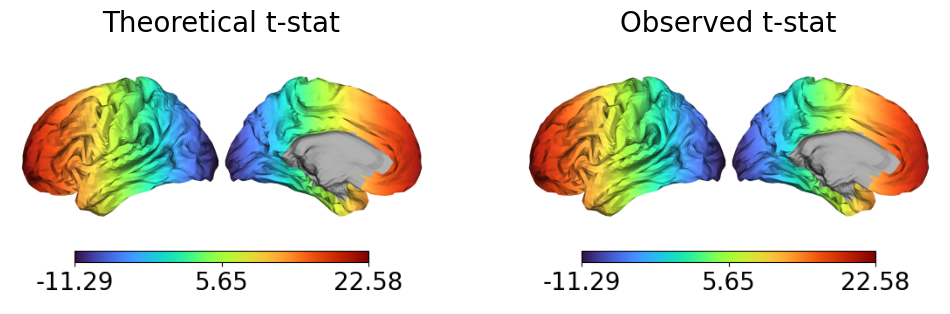

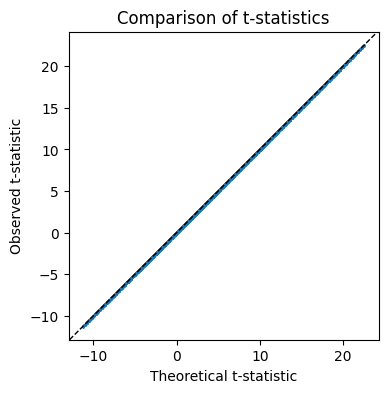

In [128]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
plot_surf(bssurf, solver.unmask_data(t_expected), cbar=True, ax=axs[0], labels=['Theoretical t-stat'])
plot_surf(bssurf, solver.unmask_data(t_observed), cbar=True, ax=axs[1], labels=['Observed t-stat'])
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.scatter(t_expected, t_observed, s=1)
ax.axline((0,0), slope=1, color='k', linestyle='--', linewidth=1)
ax.axis('equal')
ax.set_xlabel('Theoretical t-statistic')
ax.set_ylabel('Observed t-statistic')
ax.set_title('Comparison of t-statistics')
plt.show()


And see that the error is at the level of machine precision: 

In [129]:
max_abs_error = np.max(np.abs(t_observed - t_expected))
print(f"Max error from theoretical t-stat: {max_abs_error:.2e}")

Max error from theoretical t-stat: 1.78e-14


## Generating non-parametric p-values by permutation testing

First, we generate the null t-statistic maps. This is done by shuffling the design matrix (equivalent to randomising the group allocation in this example) and then computing new t-statistics at each vertex for each permutation. We use the function `mbm_generate_stat_maps` for this: 

In [130]:
# This takes around n_permutations/10 seconds
t_permuted = mbm.mbm_generate_stat_maps(design, response, contrast, statTest, 
                                     n_permutations=n_permutations, 
                                     permutationMethod=permutationMethod)

assert t_permuted.shape == (n_verts, n_permutations), \
        f"t_permuted shape {t_permuted.shape} does not match expected shape {(n_verts, n_permutations)}"

We can then compute the p-value at each vertex. In the present example, we do this using the simplest approach of counting how many null t-statistics are above/below the observed statistic. This is done with the function `mbm_calc_p_vals`: 

In [ ]:
p_observed = mbm.mbm_calc_p_vals(t_observed, t_permuted, alternative, None)

We can compare the expected and observed p-values: 

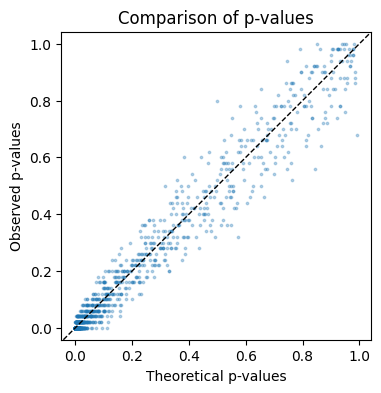

In [109]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4))

ax.scatter(p_expected, p_observed, alpha=0.3, s=3)
ax.axis("equal")
ax.axline((0, 0), slope=1, color="k", linestyle="--", linewidth=1)
ax.set_xlabel("Theoretical p-values")
ax.set_ylabel("Observed p-values")
ax.set_title("Comparison of p-values")

plt.show()

We can visualise the p-value at each vertex. As expected, the p-value is high (~1) when the spatial pattern is near zero, and is low (~0) when the spatial pattern is far from zero. 

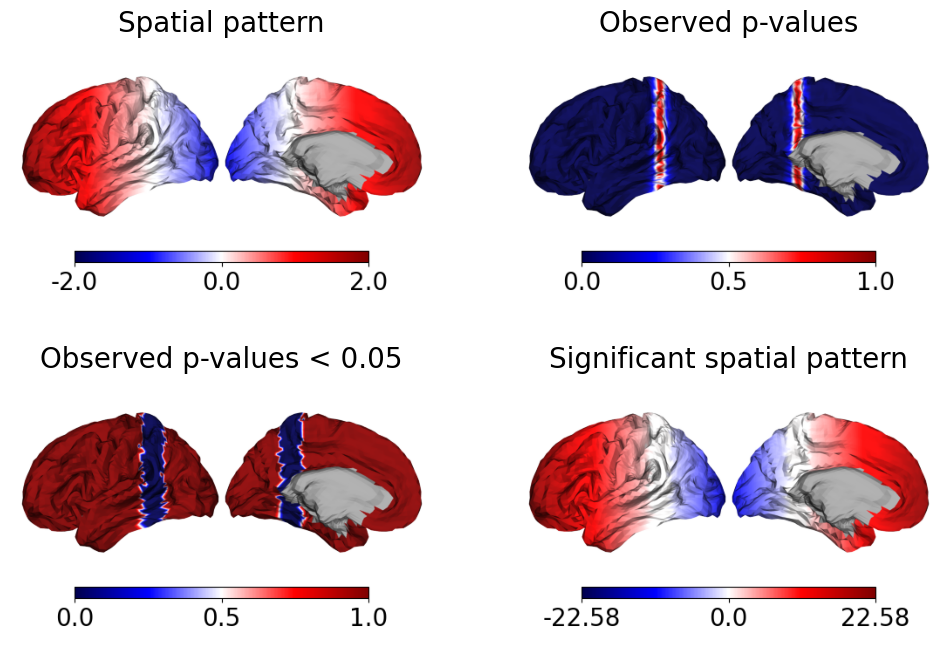

In [106]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs = axs.flatten()

plot_surf(bssurf, solver.unmask_data(spatial_pattern), labels=['Spatial pattern'],
          cmap='seismic', center=0, cbar=True, ax=axs[0])

plot_surf(bssurf, solver.unmask_data(p_observed), labels=['Observed p-values'],
          cmap='seismic', color_range=(0.00, 1.00), cbar=True, ax=axs[1])

plot_surf(bssurf, solver.unmask_data(p_observed<0.05), labels=['Observed p-values < 0.05'],
          cmap='seismic', color_range=(0.00, 1.00), cbar=True, ax=axs[2])

plot_surf(bssurf, solver.unmask_data((p_observed<0.05)*t_observed), labels=['Significant spatial pattern'], 
          cmap='seismic', center=0, cbar=True, ax=axs[3])

We can compare the observed and expected t-statistics and p-values: 

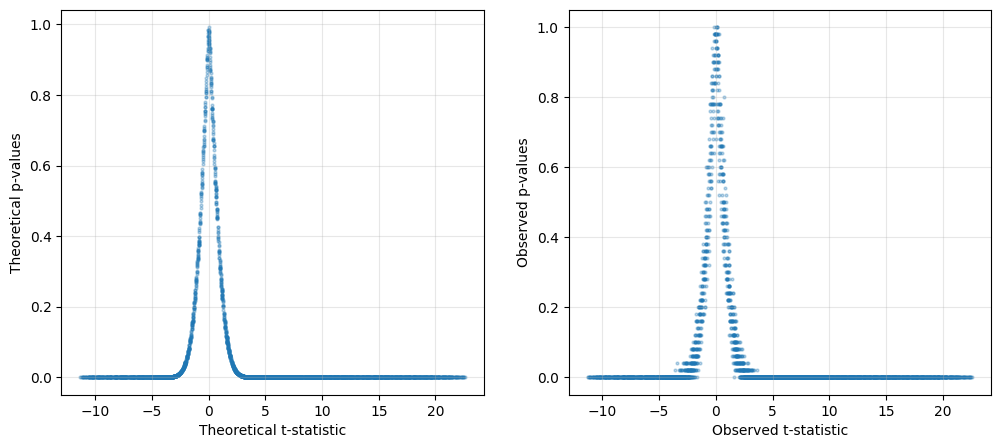

In [135]:
fig, axs = plt.subplots(1, 2, figsize=(12,5))
ax = axs[0]
ax.scatter(t_expected, p_expected, s=4, alpha=0.3)
ax.set_xlabel('Theoretical t-statistic')
ax.set_ylabel('Theoretical p-values')
ax.grid(alpha=0.3)

ax = axs[1]
ax.scatter(t_observed, p_observed, s=4, alpha=0.3)
ax.set_xlabel('Observed t-statistic')
ax.set_ylabel('Observed p-values')
ax.grid(alpha=0.3)

plt.show()

## _Fewer permutations, more accurate p-values_

Here we use the methods of Knijenberg et al. (2009) to increase the accuracy of the p-value estimation. In brief, a tail is fit to the existing t-statistics, and the p-value is interpolated. This is more accurate than using the naive count. 

Note that this method has been previously implemented in MATLAB(R) in the PALM (Permutation Analysis of Linear Models) toolbox by Winkler et al. Note that our implementation uses the original description by Knijenberg et al. (2009), not the implementation by Winkler et al.

We start by generating synthetic t-stats from a t-distribution: 


In [ ]:
temp = 300
n_permutations = 1000
t_observed = np.full(temp, np.nan)
t_permuted = np.full((temp, n_permutations), np.nan)

c = np.random.default_rng().random(temp) - 0.3
loc = np.random.default_rng().random(temp)
scale = np.random.default_rng().random(temp)

p_target = np.arange(temp) / temp

for i in range(temp):
    gpd = stats.genpareto(loc=loc[i], scale=scale[i], c=c[i])
    t_observed[i] = gpd.ppf(1 - p_target[i])
    t_permuted[i] = gpd.rvs(n_permutations)


p_naive = mbm.mbm_calc_p_vals(t_observed, t_permuted, 'greater', None)
p_fit = mbm.mbm_calc_p_vals(t_observed, t_permuted, 'greater', 
                            n_for_pval_recalculation=n_permutations, 
                            n_for_tail_estimation=n_permutations, 
                            gof_acceptance_level=0.00)




In [111]:
# print(p_target)
# print(p_naive)
# print(p_fit)

In [ ]:
# print(t_observed[12])
# print(t_permuted[12])

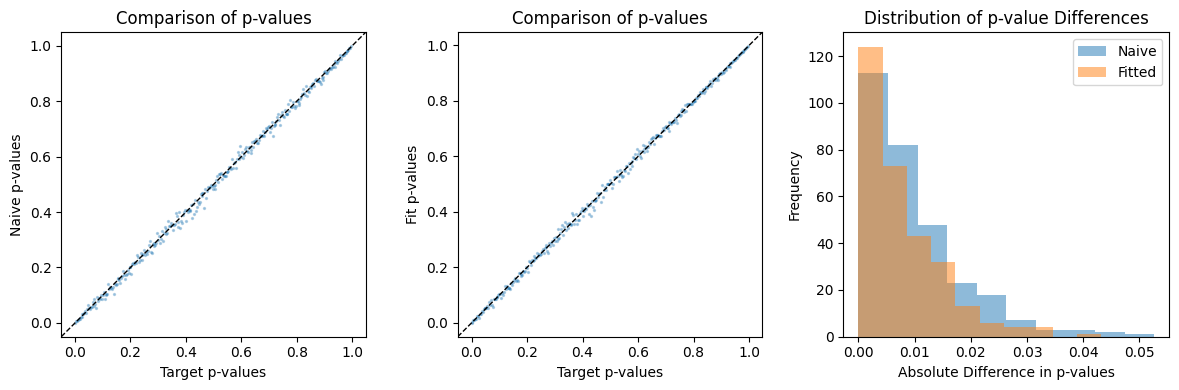

In [113]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
ax = axs[0]
ax.scatter(p_target, p_naive, s=2, alpha=0.3)
ax.axis('square')
ax.axline((0, 0), slope=1, color='k', linestyle='--', linewidth=1)
ax.set_xlabel('Target p-values')
ax.set_ylabel('Naive p-values')
ax.set_title('Comparison of p-values')

ax = axs[1]
ax.scatter(p_target, p_fit, s=2, alpha=0.3)
ax.axis('square')
ax.axline((0, 0), slope=1, color='k', linestyle='--', linewidth=1)
ax.set_xlabel('Target p-values')
ax.set_ylabel('Fit p-values')
ax.set_title('Comparison of p-values')

ax = axs[2]
ax.hist(np.abs(p_naive-p_target), alpha=0.5, label='Naive')
ax.hist(np.abs(p_fit-p_target), alpha=0.5, label='Fitted')
ax.legend()
ax.set_xlabel('Absolute Difference in p-values')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of p-value Differences')

plt.tight_layout()
plt.show()

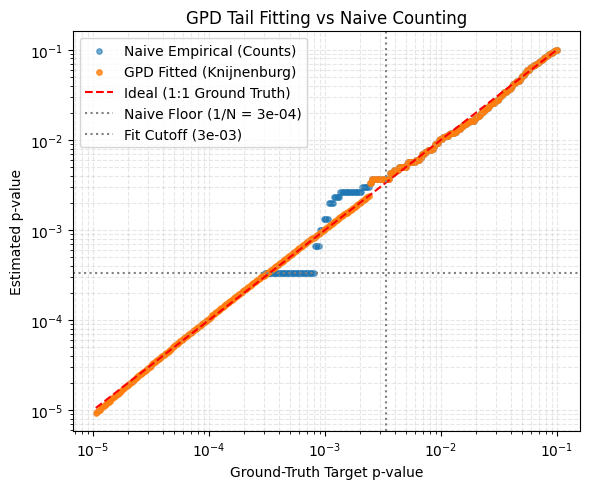

In [137]:


# 1. Setup synthetic test data
n_vertices = solver.n_verts // 10
n_permutations = 3000
n_for_pval_reconstruction = 9
df = 2 * n_subjects - 2


# Logarithmically space ground-truth p-values
# Generally GPD fitting is best ~1-2 orders of magnitude below p_naive (1/n_permutations)
p_target = np.logspace(-np.log10(n_permutations)-1.5, -1, n_vertices)

# Null distribution per vertex (e.g., Standard Normal)
t_permuted = np.random.default_rng(42).standard_t(df=df, size=(n_vertices, n_permutations))
t_permuted = np.repeat(np.random.default_rng(42).standard_t(df=df, size=(1, n_permutations)), n_vertices, axis=0)

# Generate observed statistics matching exact theoretical quantiles of the null
t_observed = stats.t.ppf(1 - p_target, df=df)

# 2. Compute Naive vs. Knijnenburg GPD Fitted p-values
p_naive = mbm.mbm_calc_p_vals(
    t_observed, t_permuted, alternative='greater', 
    n_for_pval_recalculation=None
)

p_fit = mbm.mbm_calc_p_vals(
    t_observed, t_permuted, alternative='greater', 
    n_for_pval_recalculation=n_for_pval_reconstruction,
    # n_for_tail_estimation=tuple(range(n_permutations//10, 10, -5)), 
    gof_acceptance_level=0.05
)



# 3. Visualization
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(p_target, p_naive, s=15, alpha=0.6, label='Naive Empirical (Counts)')
ax.scatter(p_target, p_fit, s=15, alpha=0.8, label='GPD Fitted (Knijnenburg)')
ax.plot(p_target, p_target, 'r--', label='Ideal (1:1 Ground Truth)')
ax.axhline(1 / n_permutations, color='gray', linestyle=':', label=f'Naive Floor (1/N = {1/n_permutations:.0e})')
ax.axvline((n_for_pval_reconstruction+1) / n_permutations, color='gray', linestyle=':', label=f'Fit Cutoff ({(n_for_pval_reconstruction+1)/n_permutations:.0e})')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Ground-Truth Target p-value')
ax.set_ylabel('Estimated p-value')
ax.set_title('GPD Tail Fitting vs Naive Counting')
ax.legend()
plt.grid(True, which="both", ls="--", alpha=0.3)
plt.tight_layout()
plt.show()


(array([  3.,  24., 110., 381., 733., 878., 554., 255.,  51.,  11.]),
 array([-3.85763428, -3.1264924 , -2.39535051, -1.66420863, -0.93306675,
        -0.20192487,  0.52921702,  1.2603589 ,  1.99150078,  2.72264267,
         3.45378455]),
 <BarContainer object of 10 artists>)

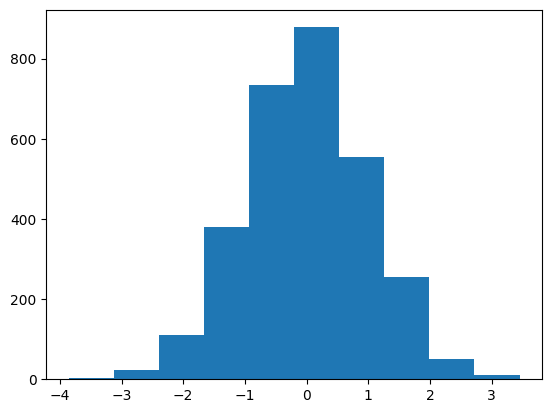